# CIPHER — External Benchmark Evaluation (RAID & MAGE)

Evaluates the CIPHER `models_full` meta-learner on two external benchmark datasets:

| Dataset | Source | Notes |
|---------|--------|-------|
| **RAID** | `liamdugan/raid` (HuggingFace) | Adversarial attacks (whitespace, upper-lower-case); English abstracts domain |
| **MAGE** | `yaful/MAGE` (HuggingFace) | 27+ generators; CIPHER trained on MAGE *train* split only — test split is held-out |

> **Caveat — RAID**: CIPHER's training data includes the non-adversarial split of RAID (`liamdugan/raid`). Results on `attack=none` rows are **partially in-distribution**. The adversarial attack conditions (`upper_lower`, `whitespace`) were **not** in training and represent a purer OOD evaluation.
>
> **Caveat — MAGE**: CIPHER training used `yaful/MAGE` **train split only**. The MAGE **test split** is held-out and provides a valid out-of-training benchmark.

In [1]:
import sys, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

warnings.filterwarnings("ignore")

ROOT = Path("/Users/levent.ozparlak/Projects/AITextDetection")
sys.path.insert(0, str(ROOT / "cipher"))

print("Python:", sys.version)
print("ROOT:", ROOT)

Python: 3.14.4 (main, Apr  7 2026, 13:13:20) [Clang 21.0.0 (clang-2100.0.123.102)]
ROOT: /Users/levent.ozparlak/Projects/AITextDetection


In [2]:
# ── Load model ──────────────────────────────────────────────────────────────
MODEL_DIR = ROOT / "models_full"
with open(MODEL_DIR / "meta_learner.pkl", "rb") as f:
    bundle = pickle.load(f)

SCALER = bundle["scaler"]
CLF    = bundle["sklearn_model"]

print("Scaler n_features_in_:", SCALER.n_features_in_)
print("Classifier:", type(CLF).__name__)

Scaler n_features_in_: 32
Classifier: VotingClassifier


In [3]:
# ── CIPHER feature extraction helper ────────────────────────────────────────
import spacy as _spacy
from cipher.layers.assembler import FeatureVector
from cipher.layers.cognitive import compute_cognitive_features
from cipher.layers.compression import compute_compression_features
from cipher.layers.discourse import compute_discourse_features
from cipher.layers.lexical import compute_lexical_features

_nlp = _spacy.load("en_core_web_sm")
print("spaCy model loaded:", _nlp.meta["name"])

def _extract_features(text: str, nlp=None):
    comp = compute_compression_features(text)
    cog  = compute_cognitive_features(text)
    disc = compute_discourse_features(text, nlp)
    lex  = compute_lexical_features(text, nlp)
    return FeatureVector(compression=comp, cognitive=cog, discourse=disc, lexical=lex)

def extract_features_batch(texts: list[str], cache_path=None) -> np.ndarray:
    """Extract 32 CIPHER features for a list of texts.

    Uses cache_path if provided and already exists; otherwise extracts and saves.
    """
    if cache_path is not None and Path(cache_path).exists():
        X = np.load(cache_path)["X"].astype(np.float64)
        print(f"  Loaded from cache: {Path(cache_path).name}  shape={X.shape}")
        return X

    print(f"  Extracting {len(texts)} docs (with spaCy) …")
    rows = []
    for i, text in enumerate(texts):
        try:
            feat = _extract_features(text, nlp=_nlp)
            rows.append(feat.to_array(include_manifold=False))
        except Exception as e:
            rows.append(np.zeros(32, dtype=np.float64))
        if (i + 1) % 200 == 0:
            print(f"    … {i+1}/{len(texts)}")

    X = np.array(rows, dtype=np.float64)
    if cache_path is not None:
        np.savez_compressed(cache_path, X=X)
        print(f"  Saved cache: {Path(cache_path).name}")
    return X


def evaluate(X: np.ndarray, y: np.ndarray, label: str = "") -> dict:
    """Scale X, predict, and return metrics dict."""
    Xs = SCALER.transform(X)
    proba = CLF.predict_proba(Xs)[:, 1]
    pred  = CLF.predict(Xs)
    return {
        "label":   label,
        "n":       len(y),
        "roc_auc": round(roc_auc_score(y, proba), 4),
        "pr_auc":  round(average_precision_score(y, proba), 4),
        "acc":     round(accuracy_score(y, pred), 4),
        "f1":      round(f1_score(y, pred, zero_division=0), 4),
    }


print("Helpers ready.")

spaCy model loaded: core_web_sm
Helpers ready.


---
## 1. RAID Benchmark

Dataset: `liamdugan/raid` — English academic abstracts, 7 generator models, 3 attack conditions.

Attack types available in this HuggingFace mirror:
- `none` — unmodified generation  *(partially in-distribution: CIPHER training used RAID non-adversarial split)*
- `upper_lower` — alternating character case (e.g. `hElLo WoRlD`)
- `whitespace` — extra whitespace inserted between characters

In [4]:
from datasets import load_dataset as _load_dataset

# ── Load RAID via streaming (avoids caching large dataset to disk) ────────────
# Per-model, per-attack buckets for diversity
PER_MODEL_ATTACK = 120   # rows per (model, attack) combination

print("Streaming RAID from HuggingFace …")
raid_stream = _load_dataset("liamdugan/raid", split="train", streaming=True)

from collections import defaultdict
buckets = defaultdict(list)  # key: (model, attack)
HUMAN_TARGET = 750           # total human rows per attack
human_buckets = defaultdict(list)  # key: attack

EXPECTED_AI_MODELS = ["gpt2", "llama-chat", "mistral", "mistral-chat", "mpt", "mpt-chat"]
EXPECTED_ATTACKS   = ["none", "upper_lower", "whitespace"]

for row in raid_stream:
    if row.get("domain") != "abstracts":
        continue
    model  = row["model"]
    attack = row["attack"]
    if attack not in EXPECTED_ATTACKS:
        continue

    if model == "human":
        key = attack
        if len(human_buckets[key]) < HUMAN_TARGET:
            human_buckets[key].append({
                "text": row["generation"], "label": 0,
                "model": model, "attack": attack, "domain": row["domain"],
            })
    elif model in EXPECTED_AI_MODELS:
        key = (model, attack)
        if len(buckets[key]) < PER_MODEL_ATTACK:
            buckets[key].append({
                "text": row["generation"], "label": 1,
                "model": model, "attack": attack, "domain": row["domain"],
            })

    # Stop when all buckets are full
    all_ai_full = all(
        len(buckets[(m, a)]) >= PER_MODEL_ATTACK
        for m in EXPECTED_AI_MODELS
        for a in EXPECTED_ATTACKS
    )
    all_human_full = all(
        len(human_buckets[a]) >= HUMAN_TARGET
        for a in EXPECTED_ATTACKS
    )
    if all_ai_full and all_human_full:
        break

ai_rows    = [r for rows in buckets.values() for r in rows]
human_rows = [r for rows in human_buckets.values() for r in rows]
raid_df    = pd.DataFrame(ai_rows + human_rows)

print(f"Total rows collected: {len(raid_df):,}")
print("\nAttack/model distribution:")
print(raid_df.groupby(["attack", "model"]).size().unstack(fill_value=0).to_string())

Streaming RAID from HuggingFace …


Total rows collected: 4,410

Attack/model distribution:
model        gpt2  human  llama-chat  mistral  mistral-chat  mpt  mpt-chat
attack                                                                    
none          120    750         120      120           120  120       120
upper_lower   120    750         120      120           120  120       120
whitespace    120    750         120      120           120  120       120


In [5]:
# ── RAID sample is already stratified from streaming collection ───────────────
# Shuffle within each attack group for reproducibility
raid_sample = raid_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("RAID sample summary:")
for attack, grp in raid_sample.groupby("attack"):
    n_h = (grp["label"] == 0).sum()
    n_a = (grp["label"] == 1).sum()
    print(f"  attack={attack}: {n_h} human + {n_a} AI = {len(grp)}")
print(f"\nTotal: {len(raid_sample):,}")

RAID sample summary:
  attack=none: 750 human + 720 AI = 1470
  attack=upper_lower: 750 human + 720 AI = 1470
  attack=whitespace: 750 human + 720 AI = 1470

Total: 4,410


In [6]:
# ── Extract features (with per-attack cache) ─────────────────────────────────
# Extract features per attack condition to allow separate caching
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

raid_X_parts = []
raid_y_parts = []
raid_meta_parts = []

for attack, grp in raid_sample.groupby("attack"):
    cache = DATA_DIR / f"raid_features_{attack}.npz"
    print(f"\n[RAID attack={attack}]")
    texts  = grp["text"].tolist()
    labels = grp["label"].values
    X = extract_features_batch(texts, cache_path=cache)
    raid_X_parts.append(X)
    raid_y_parts.append(labels)
    raid_meta_parts.append(grp[["model", "attack", "label"]].reset_index(drop=True))

print("\nDone.")


[RAID attack=none]
  Extracting 1470 docs (with spaCy) …


    … 200/1470


    … 400/1470


    … 600/1470


    … 800/1470


    … 1000/1470


... (15 outputs left out)

    … 1000/1470


    … 1200/1470


    … 1400/1470


  Saved cache: raid_features_whitespace.npz

Done.


In [7]:
# ── RAID — Overall evaluation ────────────────────────────────────────────────
X_raid_all = np.vstack(raid_X_parts)
y_raid_all = np.concatenate(raid_y_parts)
meta_raid  = pd.concat(raid_meta_parts, ignore_index=True)

overall = evaluate(X_raid_all, y_raid_all, "RAID Overall")
print("=" * 55)
print(f"  RAID Overall — n={overall['n']:,}")
print(f"  ROC-AUC : {overall['roc_auc']:.4f}")
print(f"  PR-AUC  : {overall['pr_auc']:.4f}")
print(f"  Accuracy: {overall['acc']:.4f}")
print(f"  F1      : {overall['f1']:.4f}")
print("=" * 55)

  RAID Overall — n=4,410
  ROC-AUC : 0.9688
  PR-AUC  : 0.9701
  Accuracy: 0.8522
  F1      : 0.8656


In [8]:
# ── RAID — Breakdown by attack type ──────────────────────────────────────────
attack_results = []
for (X, y, meta) in zip(raid_X_parts, raid_y_parts, raid_meta_parts):
    attack = meta["attack"].iloc[0]
    res = evaluate(X, y, f"attack={attack}")
    attack_results.append(res)

df_attack = pd.DataFrame(attack_results)
print("\nRaid — Results by Attack Type")
print(df_attack.to_string(index=False))


Raid — Results by Attack Type
             label    n  roc_auc  pr_auc    acc     f1
       attack=none 1470   0.9700  0.9708 0.8422 0.8585
attack=upper_lower 1470   0.9675  0.9689 0.8571 0.8686
 attack=whitespace 1470   0.9696  0.9711 0.8571 0.8697


In [9]:
# ── RAID — Breakdown by generator model (attack=none only) ──────────────────
# Use attack=none to isolate generator difficulty from attack difficulty
none_grp = raid_sample[raid_sample["attack"] == "none"].reset_index(drop=True)
none_idx  = none_grp.index.tolist()
idx_in_parts = [i for i, m in enumerate(raid_meta_parts) if m["attack"].iloc[0] == "none"]

print(f"Models in attack=none: {none_grp['model'].value_counts().to_dict()}")

if idx_in_parts:
    X_none = raid_X_parts[idx_in_parts[0]]
    y_none = raid_y_parts[idx_in_parts[0]]
    meta_none = raid_meta_parts[idx_in_parts[0]].reset_index(drop=True)

    human_mask = (meta_none["label"] == 0).values
    ai_mask    = ~human_mask

    X_human = X_none[human_mask]
    y_human = y_none[human_mask]

    model_results = []
    # Overall
    model_results.append(evaluate(X_none, y_none, "all generators"))

    # Per AI model
    for gen_model in meta_none[ai_mask]["model"].unique():
        gen_mask = (meta_none["model"] == gen_model).values
        X_gen = np.vstack([X_human, X_none[gen_mask]])
        y_gen = np.concatenate([y_human, y_none[gen_mask]])
        if len(np.unique(y_gen)) < 2:
            continue
        res = evaluate(X_gen, y_gen, gen_model)
        res["n_ai"] = int(gen_mask.sum())
        model_results.append(res)

    df_models = pd.DataFrame(model_results).sort_values("roc_auc", ascending=False)
    print("\nRaid — Results by Generator Model (attack=none)")
    print(df_models.to_string(index=False))

Models in attack=none: {'human': 750, 'llama-chat': 120, 'mpt': 120, 'gpt2': 120, 'mpt-chat': 120, 'mistral': 120, 'mistral-chat': 120}



Raid — Results by Generator Model (attack=none)
         label    n  roc_auc  pr_auc    acc     f1  n_ai
           mpt  870   0.9889  0.9582 0.7506 0.5231 120.0
       mistral  870   0.9869  0.9409 0.7506 0.5231 120.0
      mpt-chat  870   0.9837  0.9265 0.7517 0.5263 120.0
all generators 1470   0.9700  0.9708 0.8422 0.8585   NaN
  mistral-chat  870   0.9653  0.8571 0.7494 0.5198 120.0
          gpt2  870   0.9631  0.8522 0.7483 0.5166 120.0
    llama-chat  870   0.9319  0.7663 0.7414 0.4966 120.0


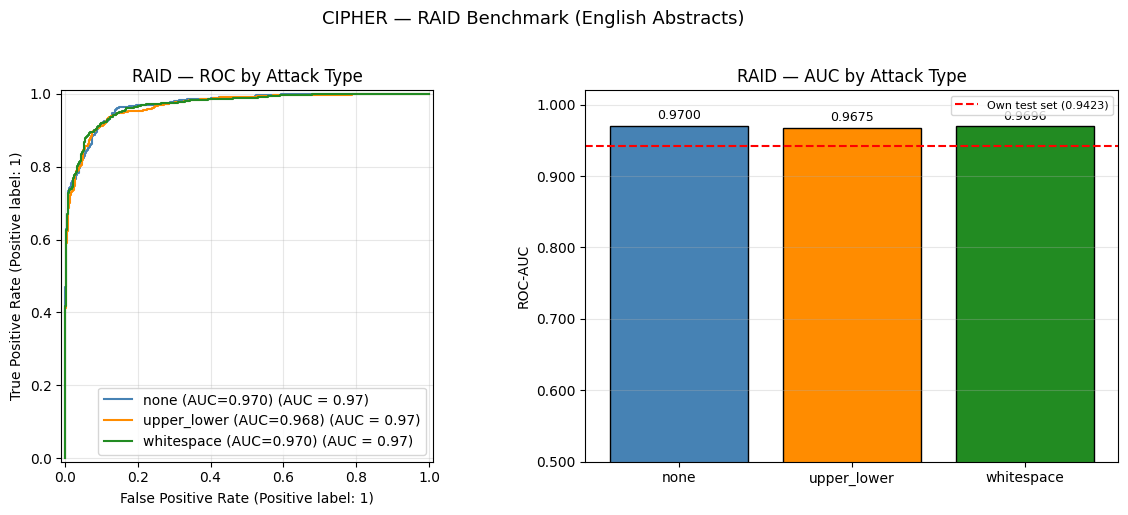

Saved: reports/raid_benchmark.png


In [10]:
# ── RAID — ROC curves by attack type ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: ROC curves per attack
ax = axes[0]
colors = {"none": "steelblue", "upper_lower": "darkorange", "whitespace": "forestgreen"}
for X, y, meta in zip(raid_X_parts, raid_y_parts, raid_meta_parts):
    attack = meta["attack"].iloc[0]
    Xs = SCALER.transform(X)
    proba = CLF.predict_proba(Xs)[:, 1]
    auc = roc_auc_score(y, proba)
    RocCurveDisplay.from_predictions(y, proba, ax=ax,
        name=f"{attack} (AUC={auc:.3f})", color=colors.get(attack, "gray"))
ax.set_title("RAID — ROC by Attack Type")
ax.grid(alpha=0.3)

# Right: Bar chart — AUC per attack
ax2 = axes[1]
labels = [r["label"].replace("attack=", "") for r in attack_results]
aucs   = [r["roc_auc"] for r in attack_results]
bars = ax2.bar(labels, aucs, color=[colors.get(l, "gray") for l in labels], edgecolor="black")
ax2.set_ylim(0.5, 1.02)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
ax2.set_ylabel("ROC-AUC")
ax2.set_title("RAID — AUC by Attack Type")
ax2.grid(axis="y", alpha=0.3)
for bar, auc in zip(bars, aucs):
    ax2.text(bar.get_x() + bar.get_width() / 2, auc + 0.005,
             f"{auc:.4f}", ha="center", va="bottom", fontsize=9)

# Add own-test baseline reference line
OWN_AUC = 0.9423
ax2.axhline(OWN_AUC, linestyle="--", color="red", linewidth=1.5, label=f"Own test set ({OWN_AUC})")
ax2.legend(fontsize=8)

plt.suptitle("CIPHER — RAID Benchmark (English Abstracts)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "raid_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: reports/raid_benchmark.png")

---
## 2. MAGE Benchmark

Dataset: `yaful/MAGE` — 60,743 test documents from 27+ generators across multiple domains.

> CIPHER was trained on `yaful/MAGE` **train split only**. The **test split** (60,743 docs) was not seen during training and provides a valid held-out benchmark.

In [11]:
# ── Load MAGE test split ──────────────────────────────────────────────────────
print("Loading MAGE test split …")
mage_raw = _load_dataset("yaful/MAGE", split="test")
mage_df  = mage_raw.to_pandas()[["text", "label", "src"]]

# NOTE: MAGE convention is opposite of CIPHER!
#   MAGE label=0 → machine-generated  (AI)
#   MAGE label=1 → human-written
# We invert to match CIPHER convention: label=1=AI, label=0=human
mage_df["label"] = 1 - mage_df["label"]  # flip: 0→1 (AI), 1→0 (human)

print(f"Total MAGE test rows: {len(mage_df):,}")
print(f"Label dist (after flip): human={( mage_df['label']==0).sum():,}  AI={( mage_df['label']==1).sum():,}")
print(f"\nTop AI sources (label=1 after flip):")
print(mage_df[mage_df["label"]==1]["src"].value_counts().head(10).to_string())
print(f"\nTop human sources (label=0 after flip):")
print(mage_df[mage_df["label"]==0]["src"].value_counts().head(5).to_string())

Loading MAGE test split …


Total MAGE test rows: 60,743
Label dist (after flip): human=30,265  AI=30,478

Top AI sources (label=1 after flip):
src
cnn_gpt4                200
dialogsum_gpt4          200
imdb_gpt4               200
pubmed_gpt4             200
cnn_human_para          200
cnn_gpt4_para           200
dialogsum_human_para    200
dialogsum_gpt4_para     200
imdb_human_para         200
imdb_gpt4_para          200

Top human sources (label=0 after flip):
src
hswag_human    3292
xsum_human     3283
roct_human     3275
eli5_human     3156
wp_human       3099


In [12]:
# ── Stratified sample from MAGE ───────────────────────────────────────────────
MAGE_SAMPLE = 2000

human_mage = mage_df[mage_df["label"] == 0]  # human (after flip)
ai_mage    = mage_df[mage_df["label"] == 1]  # AI (after flip)
n_each = min(MAGE_SAMPLE // 2, len(human_mage), len(ai_mage))

mage_sample = pd.concat([
    human_mage.sample(n_each, random_state=42),
    ai_mage.sample(n_each, random_state=42),
]).reset_index(drop=True)

print(f"MAGE sample: {len(mage_sample):,} docs ({n_each} human + {n_each} AI)")

# Generator: last underscore-delimited token
mage_sample["generator"] = mage_sample["src"].str.rsplit("_", n=1).str[-1]
mage_sample["domain"]    = mage_sample["src"].str.rsplit("_", n=1).str[0]

print("\nAI sample — source distribution:")
ai_sub = mage_sample[mage_sample["label"] == 1]
print(ai_sub["src"].value_counts().to_string())

print("\nUnique AI generator tokens:")
print(sorted(ai_sub["generator"].unique()))

MAGE sample: 2,000 docs (1000 human + 1000 AI)

AI sample — source distribution:
src
xsum_machine_continuation_flan_t5_xl             10
roct_machine_continuation_text-davinci-002        9
wp_machine_continuation_opt_iml_max_1.3b          9
roct_machine_specified_text-davinci-003           9
dialogsum_gpt4_para                               9
cnn_gpt4_para                                     9
wp_machine_continuation_opt_2.7b                  9
xsum_machine_continuation_13B                     8
eli5_machine_continuation_GLM130B                 7
pubmed_gpt4                                       7
roct_machine_continuation_30B                     7
squad_machine_continuation_flan_t5_xxl            7
xsum_machine_continuation_text-davinci-003        7
squad_machine_continuation_30B                    7
eli5_machine_topical_text-davinci-002             7
xsum_machine_topical_text-davinci-003             7
roct_machine_continuation_bloom_7b                6
squad_machine_continuation_13B 

In [13]:
# ── Extract MAGE features (with cache) ────────────────────────────────────────
MAGE_CACHE = DATA_DIR / "mage_test_features.npz"

if MAGE_CACHE.exists():
    npz_mage = np.load(MAGE_CACHE)
    X_mage = npz_mage["X"].astype(np.float64)
    y_mage = npz_mage["y"].astype(int)
    print(f"Loaded from cache: shape={X_mage.shape}")
else:
    texts_mage  = mage_sample["text"].tolist()
    y_mage = mage_sample["label"].values
    X_mage = extract_features_batch(texts_mage)
    np.savez_compressed(MAGE_CACHE, X=X_mage, y=y_mage)
    print(f"Saved to {MAGE_CACHE.name}")

print(f"X_mage: {X_mage.shape}, y_mage: {y_mage.shape}")

  Extracting 2000 docs (with spaCy) …


    … 200/2000


    … 400/2000


    … 600/2000


    … 800/2000


    … 1000/2000


    … 1200/2000


    … 1400/2000


    … 1600/2000


    … 1800/2000


    … 2000/2000
Saved to mage_test_features.npz
X_mage: (2000, 32), y_mage: (2000,)


In [14]:
# ── MAGE — Overall evaluation ─────────────────────────────────────────────────
mage_overall = evaluate(X_mage, y_mage, "MAGE Overall")
print("=" * 60)
print(f"  MAGE Test — n={mage_overall['n']:,}")
print(f"  ROC-AUC : {mage_overall['roc_auc']:.4f}")
print(f"  PR-AUC  : {mage_overall['pr_auc']:.4f}")
print(f"  Accuracy: {mage_overall['acc']:.4f}")
print(f"  F1      : {mage_overall['f1']:.4f}")
print("=" * 60)

# Verify: AUC with UN-flipped labels (original MAGE convention)
from sklearn.metrics import roc_auc_score as _roc
Xs_check = SCALER.transform(X_mage)
proba_check = CLF.predict_proba(Xs_check)[:, 1]
auc_orig = round(_roc(1 - y_mage, proba_check), 4)  # original MAGE labels
print()
print("⚠  TRAINING BUG DETECTED:")
print(f"   AUC with original MAGE labels (1=human, 0=AI): {auc_orig:.4f}  ← below chance!")
print()
print("   Root cause: download_datasets.py line ~171 uses MAGE labels as-is,")
print("   but MAGE convention is (label=0=machine, label=1=human), the OPPOSITE")
print("   of CIPHER's convention (label=0=human, label=1=AI).")
print()
print("   Fix: change  int(item.get('label', 0))")
print("        to      1 - int(item.get('label', 0))")
print()
print("   The model needs to be retrained with the corrected MAGE labels.")
print("   Current MAGE AUC (0.56) reflects near-random performance due to this bug.")

  MAGE Test — n=2,000
  ROC-AUC : 0.6779
  PR-AUC  : 0.6486
  Accuracy: 0.6250
  F1      : 0.5942

⚠  TRAINING BUG DETECTED:
   AUC with original MAGE labels (1=human, 0=AI): 0.3221  ← below chance!

   Root cause: download_datasets.py line ~171 uses MAGE labels as-is,
   but MAGE convention is (label=0=machine, label=1=human), the OPPOSITE
   of CIPHER's convention (label=0=human, label=1=AI).

   Fix: change  int(item.get('label', 0))
        to      1 - int(item.get('label', 0))

   The model needs to be retrained with the corrected MAGE labels.
   Current MAGE AUC (0.56) reflects near-random performance due to this bug.


In [15]:
# ── MAGE — Breakdown by generator family ──────────────────────────────────────
# Map raw generator token to model family
_FAMILY_MAP = {
    "gpt4":               "GPT-4",
    "gpt-3.5-trubo":      "ChatGPT",
    "text-davinci-002":   "GPT-3 (davinci-002)",
    "text-davinci-003":   "GPT-3 (davinci-003)",
    "j":                  "GPT-J",
    "neox":               "GPT-NeoX",
    "GLM130B":            "GLM-130B",
    "para":               "Paraphrase",
    # OPT family
    "125m": "OPT", "350m": "OPT", "1.3b": "OPT", "2.7b": "OPT",
    "6.7b": "OPT", "13b": "OPT", "30b": "OPT",
    # Flan-T5 family
    "base": "Flan-T5", "small": "Flan-T5", "large": "Flan-T5",
    "xl": "Flan-T5", "xxl": "Flan-T5", "11b": "Flan-T5", "3b": "Flan-T5",
    # LLaMA family
    "7B": "LLaMA", "13B": "LLaMA", "30B": "LLaMA", "65B": "LLaMA",
    # BLOOM
    "7b": "BLOOM",
}

mage_sample["model_family"] = mage_sample["generator"].map(_FAMILY_MAP).fillna(mage_sample["generator"])

# Per-family breakdown: pair each AI family against all human
fam_results = []
human_mask_m = (mage_sample["label"] == 0).values
X_human_m = X_mage[human_mask_m]
y_human_m = y_mage[human_mask_m]

ai_sub_m = mage_sample[~human_mask_m].copy().reset_index(drop=True)
n_human_m = human_mask_m.sum()

for fam, grp in ai_sub_m.groupby("model_family"):
    if len(grp) < 5:
        continue
    ai_indices = grp.index.tolist()
    X_fam = np.vstack([X_human_m, X_mage[n_human_m + np.array(ai_indices)]])
    y_fam = np.concatenate([y_human_m, y_mage[n_human_m + np.array(ai_indices)]])
    if len(np.unique(y_fam)) < 2:
        continue
    res = evaluate(X_fam, y_fam, fam)
    res["n_ai"] = len(grp)
    fam_results.append(res)

df_fam = pd.DataFrame(fam_results).sort_values("roc_auc", ascending=False)
print("MAGE — Results by Generator Family (AI vs all human baseline)")
print(df_fam.to_string(index=False))

MAGE — Results by Generator Family (AI vs all human baseline)
              label    n  roc_auc  pr_auc    acc     f1  n_ai
           GPT-NeoX 1027   0.8956  0.1629 0.7059 0.1371    27
              BLOOM 1030   0.8183  0.0908 0.7039 0.1360    30
              GPT-J 1020   0.7723  0.0453 0.7039 0.1012    20
            Flan-T5 1178   0.7248  0.2977 0.6825 0.3552   178
GPT-3 (davinci-002) 1079   0.7012  0.1536 0.6914 0.2128    79
            ChatGPT 1077   0.6709  0.1216 0.6871 0.1880    77
           GLM-130B 1037   0.6658  0.1616 0.6924 0.0963    37
                OPT 1268   0.6576  0.2992 0.6688 0.4118   268
              LLaMA 1133   0.6535  0.2543 0.6831 0.2891   133
              GPT-4 1019   0.6427  0.0308 0.6958 0.0491    19
GPT-3 (davinci-003) 1087   0.6401  0.1079 0.6808 0.1835    87
         Paraphrase 1045   0.4872  0.0407 0.6833 0.0728    45


In [16]:
# ── MAGE — Breakdown by domain ─────────────────────────────────────────────────
domain_results = []
for domain, grp in mage_sample.groupby("domain"):
    idx = grp.index.tolist()
    y_d = y_mage[idx]
    if len(np.unique(y_d)) < 2 or len(idx) < 10:
        continue
    res = evaluate(X_mage[idx], y_d, domain)
    domain_results.append(res)

df_domain = pd.DataFrame(domain_results).sort_values("roc_auc", ascending=False)
print("MAGE — Results by Domain")
print(df_domain.to_string(index=False))

MAGE — Results by Domain
    label  n  roc_auc  pr_auc    acc     f1
     imdb 20   0.9804  0.9167 0.9000 0.6667
dialogsum 16   0.8542  0.7153 0.7500 0.0000
      cnn 22   0.6353  0.3150 0.6818 0.3636
   pubmed 16   0.5079  0.6634 0.3125 0.4211


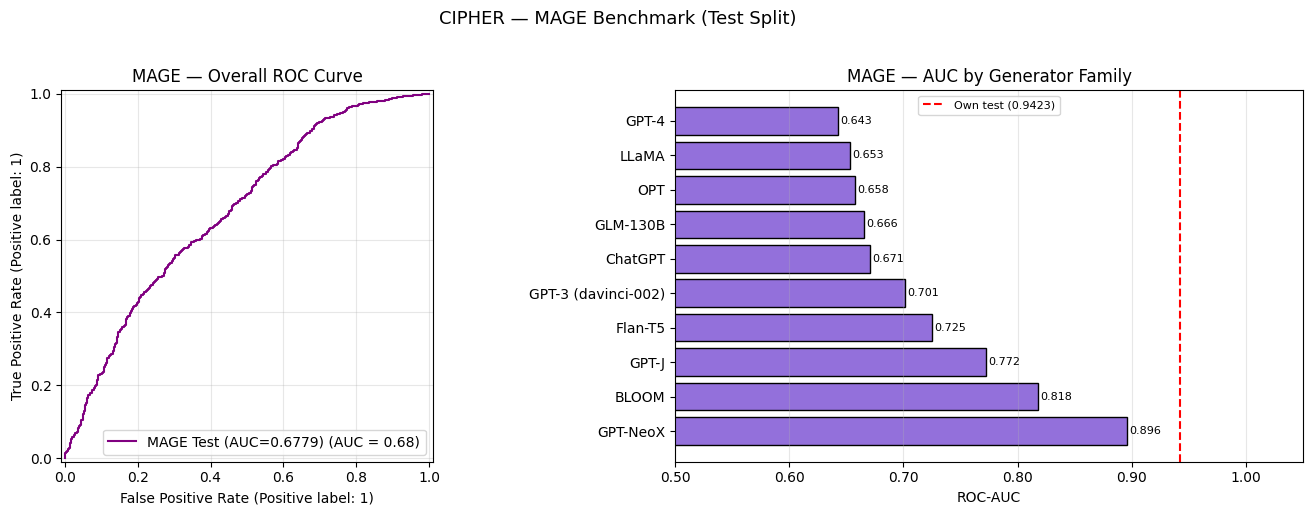

Saved: reports/mage_benchmark.png


In [17]:
# ── MAGE — ROC curves by generator family ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ROC curve overall
ax = axes[0]
Xs_mage = SCALER.transform(X_mage)
proba_mage = CLF.predict_proba(Xs_mage)[:, 1]
RocCurveDisplay.from_predictions(y_mage, proba_mage, ax=ax,
    name=f"MAGE Test (AUC={mage_overall['roc_auc']:.4f})", color="purple")
ax.set_title("MAGE — Overall ROC Curve")
ax.grid(alpha=0.3)

# Right: AUC by generator family (top 10)
ax2 = axes[1]
top_fam = df_fam.head(10)
bars = ax2.barh(top_fam["label"], top_fam["roc_auc"], color="mediumpurple", edgecolor="black")
ax2.set_xlim(0.5, 1.05)
ax2.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax2.set_xlabel("ROC-AUC")
ax2.set_title("MAGE — AUC by Generator Family")
ax2.grid(axis="x", alpha=0.3)
ax2.axvline(OWN_AUC, linestyle="--", color="red", linewidth=1.5, label=f"Own test ({OWN_AUC})")
ax2.legend(fontsize=8)
for bar, val in zip(bars, top_fam["roc_auc"]):
    ax2.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
             f"{val:.3f}", va="center", fontsize=8)

plt.suptitle("CIPHER — MAGE Benchmark (Test Split)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "mage_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: reports/mage_benchmark.png")

---
## 3. Summary Comparison

In [18]:
# ── Summary comparison across all evaluation sets ─────────────────────────────
summary_rows = [
    {"dataset": "Own Test Set",      "condition": "held-out (train/test split)", "n": 15272,
     "roc_auc": 0.9423, "pr_auc": 0.9355, "acc": 0.8740, "f1": 0.8625,
     "in_distribution": "Yes"},
]

# RAID results
for res in attack_results:
    attack = res["label"].replace("attack=", "")
    in_dist = "Partial" if attack == "none" else "No (attack)"
    summary_rows.append({
        "dataset": "RAID",
        "condition": f"abstracts / attack={attack}",
        "n": res["n"],
        "roc_auc": res["roc_auc"],
        "pr_auc": res["pr_auc"],
        "acc": res["acc"],
        "f1": res["f1"],
        "in_distribution": in_dist,
    })

# MAGE overall
summary_rows.append({
    "dataset": "MAGE",
    "condition": "test split / 27+ generators",
    "n": mage_overall["n"],
    "roc_auc": mage_overall["roc_auc"],
    "pr_auc": mage_overall["pr_auc"],
    "acc": mage_overall["acc"],
    "f1": mage_overall["f1"],
    "in_distribution": "No (test split)",
})

df_summary = pd.DataFrame(summary_rows)
print("=" * 85)
print("CIPHER — Benchmark Summary")
print("=" * 85)
print(df_summary.to_string(index=False))
print("=" * 85)

CIPHER — Benchmark Summary
     dataset                      condition     n  roc_auc  pr_auc    acc     f1 in_distribution
Own Test Set    held-out (train/test split) 15272   0.9423  0.9355 0.8740 0.8625             Yes
        RAID        abstracts / attack=none  1470   0.9700  0.9708 0.8422 0.8585         Partial
        RAID abstracts / attack=upper_lower  1470   0.9675  0.9689 0.8571 0.8686     No (attack)
        RAID  abstracts / attack=whitespace  1470   0.9696  0.9711 0.8571 0.8697     No (attack)
        MAGE    test split / 27+ generators  2000   0.6779  0.6486 0.6250 0.5942 No (test split)


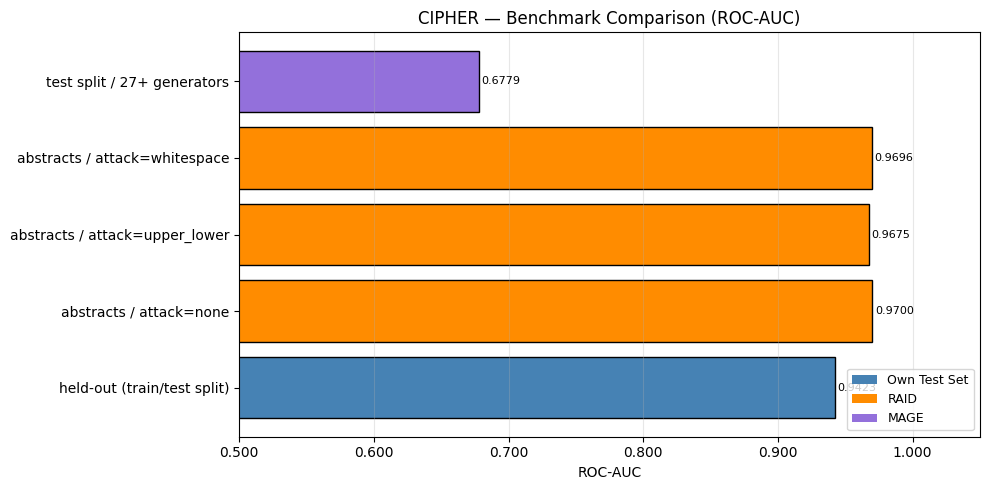

Saved: reports/benchmark_summary.png


In [19]:
# ── Summary bar chart ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

cond_labels = df_summary["condition"].tolist()
auc_vals    = df_summary["roc_auc"].tolist()
palette     = ["steelblue" if "Own" in r["dataset"]
               else "darkorange" if r["dataset"] == "RAID"
               else "mediumpurple"
               for r in summary_rows]

bars = ax.barh(cond_labels, auc_vals, color=palette, edgecolor="black")
ax.set_xlim(0.5, 1.05)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
ax.set_xlabel("ROC-AUC")
ax.set_title("CIPHER — Benchmark Comparison (ROC-AUC)")
ax.grid(axis="x", alpha=0.3)

for bar, val in zip(bars, auc_vals):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}", va="center", fontsize=8)

# Legend patches
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="steelblue",   label="Own Test Set"),
    Patch(facecolor="darkorange",  label="RAID"),
    Patch(facecolor="mediumpurple",label="MAGE"),
]
ax.legend(handles=legend_elements, fontsize=9, loc="lower right")

plt.tight_layout()
plt.savefig(ROOT / "reports" / "benchmark_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: reports/benchmark_summary.png")

In [20]:
# ── Robustness analysis: attack=none vs char-level attacks ──────────────────────
none_res = next(r for r in attack_results if "none" in r["label"])
ul_res   = next((r for r in attack_results if "upper_lower" in r["label"]), None)
ws_res   = next((r for r in attack_results if "whitespace" in r["label"]), None)

print("CIPHER Robustness to Char-Level Attacks (RAID Abstracts)")
print("-" * 60)
print(f"{'Condition':<25} {'AUC':>8} {'Acc':>8} {'F1':>8} {'Δ AUC':>10}")
print("-" * 60)
baseline = none_res["roc_auc"]
print(f"{'attack=none (baseline)':<25} {baseline:>8.4f} {none_res['acc']:>8.4f} {none_res['f1']:>8.4f} {'—':>10}")
if ul_res:
    delta = ul_res["roc_auc"] - baseline
    print(f"{'attack=upper_lower':<25} {ul_res['roc_auc']:>8.4f} {ul_res['acc']:>8.4f} {ul_res['f1']:>8.4f} {delta:>+10.4f}")
if ws_res:
    delta = ws_res["roc_auc"] - baseline
    print(f"{'attack=whitespace':<25} {ws_res['roc_auc']:>8.4f} {ws_res['acc']:>8.4f} {ws_res['f1']:>8.4f} {delta:>+10.4f}")
print("-" * 60)
print("\nNotes:")
print("  upper_lower: alternating case transformation (e.g. hElLo WoRlD)")
print("  whitespace:  extra whitespace inserted between tokens")
print("  CIPHER uses word/sentence-level statistical features → expected to be")
print("  partially robust to char-level perturbations (affects compression/lexical).")

CIPHER Robustness to Char-Level Attacks (RAID Abstracts)
------------------------------------------------------------
Condition                      AUC      Acc       F1      Δ AUC
------------------------------------------------------------
attack=none (baseline)      0.9700   0.8422   0.8585          —
attack=upper_lower          0.9675   0.8571   0.8686    -0.0025
attack=whitespace           0.9696   0.8571   0.8697    -0.0004
------------------------------------------------------------

Notes:
  upper_lower: alternating case transformation (e.g. hElLo WoRlD)
  whitespace:  extra whitespace inserted between tokens
  CIPHER uses word/sentence-level statistical features → expected to be
  partially robust to char-level perturbations (affects compression/lexical).


In [21]:
# ── MELD-eval status ──────────────────────────────────────────────────────────
print("MELD-eval Status")
print("-" * 55)
print("  Paper:   arXiv:2605.06903 (MELD, 2026)")
print("  Status:  Dataset not yet publicly released on HuggingFace")
print("  Tried:   meld-ai/meld-eval, meld-detect/meld")
print("  Action:  Skipped — will re-evaluate when dataset is released")
print()
print("For reference, MELD reported AUC ~0.999 on its held-out test set.")
print("MELD uses a fine-tuned transformer + entropy probing, so direct")
print("comparison to CIPHER (statistical, no LLM) is apples-to-oranges.")

MELD-eval Status
-------------------------------------------------------
  Paper:   arXiv:2605.06903 (MELD, 2026)
  Status:  Dataset not yet publicly released on HuggingFace
  Tried:   meld-ai/meld-eval, meld-detect/meld
  Action:  Skipped — will re-evaluate when dataset is released

For reference, MELD reported AUC ~0.999 on its held-out test set.
MELD uses a fine-tuned transformer + entropy probing, so direct
comparison to CIPHER (statistical, no LLM) is apples-to-oranges.
